In [1]:
import torch, torchvision
from torchvision import transforms
from datasets import load_dataset

C:\Users\litwi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# IMDB Sentiment Classification: RNN vs LSTM

**Goal:** predict whether a movie review is positive or negative.
**Data:** Hugging Face `imdb` (`train` 25k, `test` 25k; ignore the `unsupervised` split, it has no real labels).
**Compare:** TF-IDF + Logistic Regression (baseline) vs RNN vs LSTM.

**Pipeline:** text -> tokens -> indices -> padding / truncation (`max_len`) -> `Embedding` -> RNN/LSTM -> `Linear`

---

## Functions to write (the full list, nothing else)

| # | Function | Purpose |
|---|---|---|
| 1 | `load_imdb()` | download IMDB from Hugging Face, return the `DatasetDict` |
| 2 | `split_train_val` | reuse from the CIFAR project |
| 3 | `tokenize(text)` | lowercase, remove `<br />`, remove punctuation, split into words |
| 4 | `build_vocab(texts, max_size=10000)` | word to index, `<pad>` = 0, `<unk>` = 1 (**train only**) |
| 5 | `encode(text, vocab, max_len)` | list of indices, truncated or padded to `max_len` |
| 6 | `make_loader(texts, labels, vocab, max_len, batch_size, shuffle)` | DataLoader |
| 7 | `run_tfidf_baseline(train_texts, train_labels, val_texts, val_labels)` | returns val accuracy |
| 8 | `build_lstm(vocab_size, emb_dim, hidden_dim)` | `Embedding -> LSTM -> last hidden -> Linear(2)` (uses a small `nn.Module` class inside) |
| 9 | `fit`, `evaluate`, `count_parameters`, `plot_history` | reuse from CIFAR, adapt to text batches, add `clip_grad_norm_` |
| 10 | `run_experiment(name, model_type, hidden_dim, max_len, lr, epochs)` | one row of the results table |
| 11 | `test_final(model, test_loader, device)` | run once on the test set |

---

## Step 1. Data
- [ ] `load_imdb()` and `split_train_val`
- [ ] look at: `print(ds)`, one review text, labels of the first 10 examples (data is sorted by label, so shuffle before splitting), review length distribution (decides `max_len`)

## Step 2. Text to numbers
- [ ] `tokenize`, `build_vocab`, `encode`
- [ ] check: tokenize the first review and print the first 20 tokens

## Step 3. DataLoader
- [ ] `make_loader`
- [ ] check one batch: shape `(batch_size, max_len)`

## Step 4. Baseline without a neural network
- [ ] `run_tfidf_baseline`

## Step 5. Model
- [ ] write the tensor shape after every layer *before* coding:
  `(batch, max_len)` -> Embedding -> `(batch, max_len, emb_dim)` -> LSTM -> `(batch, hidden)` -> Linear -> `(batch, 2)`
- [ ] think: how to pick the "last" hidden state when reviews are padded?
- [ ] `build_lstm`

## Step 6. Training
- [ ] `fit`, `evaluate`, `count_parameters`, `plot_history` (adapted)
- [ ] gradient clipping

## Step 7. Experiments
- [ ] `run_experiment` + results table

| Experiment | What it tests |
|---|---|
| `nn.RNN` vs `nn.LSTM` | does LSTM handle long reviews better? |
| `max_len` 100 vs 400 | effect of sequence length |
| `hidden_dim` 32 vs 128 | model capacity |
| (optional) `bidirectional=True` | reading in both directions |
| (optional) pretrained GloVe in `Embedding` | transfer learning for words |

## Step 8. Final
- [ ] `test_final` once, on the best model chosen by validation
- [ ] comparison table: TF-IDF vs RNN vs LSTM
- [ ] short note in English: why did the results come out this way?

---

## Reading (concepts, no coding)
- Chollet ch. 6.1 (Embedding, skim the pretrained part), 6.2 (RNN, LSTM)
- GRU: simplified LSTM with two gates (`nn.GRU`)
- BPTT: backprop through time, source of the vanishing gradient
- Bidirectional RNN: what it gives, when it makes no sense
- Seq2seq bottleneck: why it led to attention
- word2vec idea: words in similar contexts get similar vectors (no implementation)

## Questions to answer in notes
1. Why is the vocabulary built only on the train set?
2. Why does a plain RNN struggle with long reviews?
3. What do the forget / input / output gates do in an LSTM?
4. What information does `Flatten` lose that an LSTM keeps?
5. Why is the `Embedding` layer the first layer, and why does it need integer indices?

## Step 1. Data
- [ ] `load_imdb()` and `split_train_val`
- [ ] look at: `print(ds)`, one review text, labels of the first 10 examples (data is sorted by label, so shuffle before splitting), review length distribution (decides `max_len`)

In [2]:
def load_imdb():
    """Download IMDB from Hugging Face and return it as a DatasetDict."""
    ds = load_dataset("stanfordnlp/imdb")
    return ds
ds = load_imdb()
ds["train"]

Dataset({
    features: ['text', 'label'],
    num_rows: 25000
})

In [3]:
ds["train"][0]["text"]

'I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far between, ev

In [4]:
from torch.utils.data import random_split

In [5]:
def split_train_val(train_data, val_size=5000, seed=42):
    """Split train_data into train and validation sets (reproducible)."""
    train_size = len(train_data) - val_size
    generator = torch.Generator().manual_seed(seed)
    train_set, val_set = random_split(train_data, [train_size, val_size], generator=generator)
    return train_set, val_set

spliting into train and val set

In [6]:
train_set, val_set = split_train_val(ds["train"])
print(f"Length of training set {len(train_set)} and val set {len(val_set)}")

Length of training set 20000 and val set 5000


## Step 2. Text to numbers
- [ ] `tokenize`, `build_vocab`, `encode`
- [ ] check: tokenize the first review and print the first 20 tokens

In [7]:
import re
from collections import Counter

In [8]:
def tokenize(text):
    """Lowercase the text, remove <br /> tags and punctuation, return a list of words."""
    # Lowercase so "Great" and "great" become the same word,
    # and replace HTML line breaks with a space so neighbouring words don't glue together
    text_lower = text.lower().replace("<br />", " ")
    # Keep only runs of letters and apostrophes (keeps "don't" as one word);
    # punctuation and digits are dropped
    tokens = re.findall(r"[a-z']+", text_lower)
    return tokens

In [9]:
tokenize(ds["train"][0]["text"])

['i',
 'rented',
 'i',
 'am',
 'curious',
 'yellow',
 'from',
 'my',
 'video',
 'store',
 'because',
 'of',
 'all',
 'the',
 'controversy',
 'that',
 'surrounded',
 'it',
 'when',
 'it',
 'was',
 'first',
 'released',
 'in',
 'i',
 'also',
 'heard',
 'that',
 'at',
 'first',
 'it',
 'was',
 'seized',
 'by',
 'u',
 's',
 'customs',
 'if',
 'it',
 'ever',
 'tried',
 'to',
 'enter',
 'this',
 'country',
 'therefore',
 'being',
 'a',
 'fan',
 'of',
 'films',
 'considered',
 'controversial',
 'i',
 'really',
 'had',
 'to',
 'see',
 'this',
 'for',
 'myself',
 'the',
 'plot',
 'is',
 'centered',
 'around',
 'a',
 'young',
 'swedish',
 'drama',
 'student',
 'named',
 'lena',
 'who',
 'wants',
 'to',
 'learn',
 'everything',
 'she',
 'can',
 'about',
 'life',
 'in',
 'particular',
 'she',
 'wants',
 'to',
 'focus',
 'her',
 'attentions',
 'to',
 'making',
 'some',
 'sort',
 'of',
 'documentary',
 'on',
 'what',
 'the',
 'average',
 'swede',
 'thought',
 'about',
 'certain',
 'political',
 'iss

In [10]:
def build_vocab(texts, max_size=10000):
    """Build a word -> index mapping from the most frequent words (train only)."""
    # Count how many times each word appears across all training reviews
    counter = Counter()
    for r in texts:
        counter.update(tokenize(r["text"]))

    # Keep the most frequent words; 2 slots are reserved for <pad> and <unk>
    top_words = counter.most_common(max_size - 2)

    # Special tokens first: 0 = padding, 1 = unknown word
    vocab = {"<pad>": 0, "<unk>": 1}

    # Give each frequent word the next free index, starting from 2
    # (most_common returns (word, count) pairs, we only need the word)
    for index, (word, count) in enumerate(top_words, start=2):
        vocab[word] = index

    return vocab

vocab = build_vocab(train_set)
print(len(vocab), vocab["the"], vocab["and"])

10000 2 3


In [11]:
def encode(text, vocab, max_len):
    """Turn a review into a list of exactly max_len word indices."""
    # 1. Text -> list of words
    tokens = tokenize(text)

    # 2. Words -> indices (words missing from the vocab get 1 = <unk>)
    indices = [vocab.get(word, 1) for word in tokens]

    # 3. Truncate: keep at most max_len indices (no effect on shorter reviews)
    indices = indices[:max_len]

    # 4. Pad: fill the remaining positions with 0 = <pad>
    indices = indices + [0] * (max_len - len(indices))

    return indices

In [12]:
print(len(encode(train_set[0]["text"], vocab, 200)))   # long review -> 200
print(encode("great movie", vocab, 10))                # short review -> 2 indices + 8 zeros

200
[85, 17, 0, 0, 0, 0, 0, 0, 0, 0]


HOW IT WORKS?

In [13]:
text = train_set[0]["text"]
tokens = tokenize(text)
indices = encode(text, vocab, 200)

print(text[:200])
print(tokens[:10])
print(indices[:10])
print(list(zip(tokens[:10], indices[:10])))

I saW this film while at Birmingham Southern College in 1975, when it was shown in combination with the Red Balloon. Both films are similar in their dream-like quality. The bulk of the film entails a 
['i', 'saw', 'this', 'film', 'while', 'at', 'birmingham', 'southern', 'college', 'in']
[10, 217, 11, 19, 134, 30, 1, 2774, 1187, 8]
[('i', 10), ('saw', 217), ('this', 11), ('film', 19), ('while', 134), ('at', 30), ('birmingham', 1), ('southern', 2774), ('college', 1187), ('in', 8)]


## Step 3. DataLoader
- [ ] `make_loader`
- [ ] check one batch: shape `(batch_size, max_len)`

In [14]:
from torch.utils.data import TensorDataset, DataLoader

In [15]:
def make_loader(texts, labels, vocab, max_len, batch_size, shuffle):
    """Encode all reviews and wrap them in a DataLoader."""
    # 1. Every review -> list of max_len indices
    encoded = []
    for text in texts:
        encoded.append(encode(text, vocab, max_len))

    # 2. List of lists -> tensor of shape (num_reviews, max_len), dtype long
    x = torch.tensor(encoded, dtype=torch.long)

    # 3. Labels -> tensor of shape (num_reviews,), dtype long
    y = torch.tensor(labels, dtype=torch.long)

    # 4. Pair each review with its label
    dataset = TensorDataset(x, y)

    # 5. Cut into batches (and shuffle if needed)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

In [16]:
# --- Step 1: split each dataset into plain lists of texts and labels ---
train_texts = [r["text"] for r in train_set]    # 20,000 raw review strings
train_labels = [r["label"] for r in train_set]  # 20,000 labels (0 = negative, 1 = positive)
val_texts = [r["text"] for r in val_set]        # 5,000 raw review strings
val_labels = [r["label"] for r in val_set]      # 5,000 labels

# --- Step 2: build the DataLoaders ---
# Arguments: texts, labels, vocab (built on train only), max_len, batch_size, shuffle
train_loader = make_loader(train_texts, train_labels, vocab, 200, 64, True)   # shuffle train every epoch
val_loader = make_loader(val_texts, val_labels, vocab, 200, 64, False)        # no need to shuffle validation

# --- Step 3: sanity check on one batch ---
xb, yb = next(iter(train_loader))
print(xb.shape, xb.dtype, yb.shape, yb.dtype)

torch.Size([64, 200]) torch.int64 torch.Size([64]) torch.int64


example

## Step 5a. Simple model (no recurrence)
- [ ] fill in the shapes *before* coding:

| Layer | Output shape |
|---|---|
| input | `(batch, max_len)` |
| `Embedding` | `(batch, max_len, emb_dim)` |
| `Flatten` | `(batch, max_len * emb_dim)` |
| `Linear` | `(batch, 2)` |

- [ ] `build_flatten_net(vocab_size, emb_dim, max_len)`
- [ ] question: what information does `Flatten` lose?

## Step 5b. LSTM model
- [ ] fill in the shapes *before* coding:

| Layer | Output shape |
|---|---|
| input | `(batch, max_len)` |
| `Embedding` | `(batch, max_len, emb_dim)` |
| `LSTM` (last hidden state) | `(batch, hidden_dim)` |
| `Linear` | `(batch, 2)` |

- [ ] question: how to pick the "last" hidden state when padding (`0`) sits at the end of the review?
- [ ] `build_lstm(vocab_size, emb_dim, hidden_dim)`

In [17]:
import torch
import torch.nn as nn

In [18]:
def build_flatten_net(vocab_size, emb_dim, max_len):
    """Simple baseline without recurrence: Embedding -> Flatten -> Linear -> ReLU -> Linear."""
    model = nn.Sequential(
        nn.Embedding(vocab_size, emb_dim),     # (batch, max_len) -> (batch, max_len, emb_dim)
        nn.Flatten(),                          # -> (batch, max_len * emb_dim)
        nn.Linear(emb_dim * max_len, 32),      # -> (batch, 32) hidden layer
        nn.ReLU(),                             # non-linearity between the two Linear layers
        nn.Linear(32, 2),                      # -> (batch, 2) scores: negative / positive (no softmax, the loss does it)
    )
    return model

In [19]:
def count_parameters(model):
    """Return the number of trainable parameters in the model."""
    # numel() = number of elements in a tensor; sum over all weight tensors
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [20]:
import matplotlib.pyplot as plt


def evaluate(model, loader, loss_fn, device):
    """Return (average loss, accuracy) of the model on a DataLoader."""
    model.eval()                       # switch off training-only behaviour (e.g. dropout)
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():              # no gradients needed for evaluation
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)                               # (batch, 2)
            loss = loss_fn(logits, yb)
            total_loss += loss.item() * len(yb)              # weight by batch size
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += len(yb)
    return total_loss / total, correct / total


def fit(model, train_loader, val_loader, epochs, lr, device, clip=1.0):
    """Train the model and return a history dict with loss and accuracy per epoch."""
    model.to(device)
    loss_fn = nn.CrossEntropyLoss()                          # takes raw scores + class indices
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()                                        # training mode
        total_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()                            # reset gradients from previous batch
            logits = model(xb)
            loss = loss_fn(logits, yb)
            loss.backward()                                  # compute gradients
            nn.utils.clip_grad_norm_(model.parameters(), clip)  # keep gradients from exploding (RNNs)
            optimizer.step()                                 # update weights
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += len(yb)

        train_loss, train_acc = total_loss / total, correct / total
        val_loss, val_acc = evaluate(model, val_loader, loss_fn, device)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        print(f"Epoch {epoch + 1}/{epochs} | train loss {train_loss:.3f} acc {train_acc:.3f} "
              f"| val loss {val_loss:.3f} acc {val_acc:.3f}")
    return history


def plot_history(history):
    """Plot loss and accuracy curves (train vs validation)."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].plot(history["train_loss"], label="train")
    axes[0].plot(history["val_loss"], label="val")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("epoch")
    axes[0].legend()
    axes[1].plot(history["train_acc"], label="train")
    axes[1].plot(history["val_acc"], label="val")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("epoch")
    axes[1].legend()
    plt.show()

In [21]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cpu


In [22]:
net = build_flatten_net(vocab_size=10000, emb_dim=16, max_len=200)
out = net(xb)           # xb: one batch from train_loader
print(out.shape)        # expected: torch.Size([64, 2])
print(count_parameters(net))

torch.Size([64, 2])
262498


calculate params

Epoch 1/10 | train loss 0.693 acc 0.528 | val loss 0.685 acc 0.551
Epoch 2/10 | train loss 0.607 acc 0.662 | val loss 0.705 acc 0.584
Epoch 3/10 | train loss 0.427 acc 0.793 | val loss 0.785 acc 0.602
Epoch 4/10 | train loss 0.287 acc 0.869 | val loss 0.925 acc 0.633
Epoch 5/10 | train loss 0.198 acc 0.914 | val loss 1.007 acc 0.657
Epoch 6/10 | train loss 0.138 acc 0.944 | val loss 1.104 acc 0.679
Epoch 7/10 | train loss 0.094 acc 0.962 | val loss 1.200 acc 0.684
Epoch 8/10 | train loss 0.060 acc 0.979 | val loss 1.333 acc 0.689
Epoch 9/10 | train loss 0.038 acc 0.987 | val loss 1.416 acc 0.696
Epoch 10/10 | train loss 0.022 acc 0.994 | val loss 1.555 acc 0.700


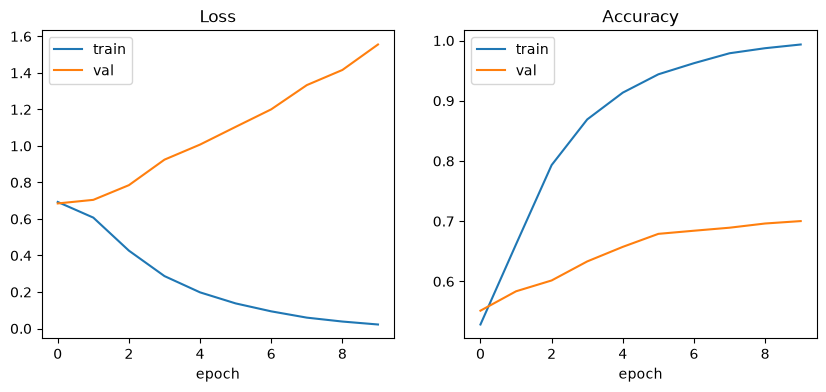

In [23]:
history = fit(net, train_loader, val_loader, epochs=10, lr=1e-3, device=device)
plot_history(history)

## Results: Embedding + Flatten (no recurrence)

| Metric | Epoch 1 | Epoch 10 |
|---|---|---|
| train acc | 0.969 | 0.997 |
| val acc | 0.696 | 0.726 |
| train loss | 0.083 | 0.011 |
| val loss | 1.278 | 2.137 |

**Observation:** strong overfitting from the very first epoch.
- Train accuracy is ~99.7%, validation accuracy only ~72%, a gap of ~27 points.
- Validation loss **increases** every epoch (1.28 -> 2.14) while train loss falls to almost zero. The model becomes more and more confident in wrong predictions.
- Validation accuracy still creeps up slightly (0.70 -> 0.73), but the loss shows the model is memorizing the training reviews, not learning general rules.

**Why it overfits:**
- The model has 262k parameters, 160k of them in `Embedding`, while we train on only 20k reviews.
- `Flatten` ties every word to a fixed position (position 5 and position 6 are treated as unrelated), so the model cannot reuse what it learned about a word at another position.
- It ignores word order and context ("not good" vs "good"), so it can only memorize word-at-position patterns.
- No regularization (no dropout, no weight decay, no early stopping).

**What this tells us:** a simple dense model on top of embeddings is a weak baseline for text. It is the reference point for the LSTM, which reads words in order and shares weights across positions.

**Ideas to improve (later experiments):**
- stop earlier (best val acc / val loss was around epoch 1-2)
- smaller `emb_dim`, dropout after `Flatten`
- LSTM instead of `Flatten`

## Step 5b. LSTM model
- [ ] fill in the shapes *before* coding:

| Layer | Output shape |
|---|---|
| input | `(batch, max_len)` |
| `Embedding` | `(batch, max_len, emb_dim)` |
| `LSTM` (last hidden state) | `(batch, hidden_dim)` |
| `Linear` | `(batch, 2)` |

- [ ] question: how to pick the "last" hidden state when padding (`0`) sits at the end of the review?
- [ ] `build_lstm(vocab_size, emb_dim, hidden_dim)`

In [32]:
class SentimentLSTM(nn.Module):
    """Embedding -> LSTM -> last hidden state -> Linear."""

    def __init__(self, vocab_size, emb_dim, hidden_dim):
        """Create the layers (runs once, when the model is built)."""
        
        super().__init__()   # required first line: sets up nn.Module internals
        
        # Word index -> vector of emb_dim numbers (index 0 = <pad>, kept as zeros)
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        
        # Reads the review word by word; keeps a summary of hidden_dim numbers
        self.lstm = nn.LSTM(emb_dim, hidden_dim, batch_first=True)
        
        # Turns the final summary into 2 scores: negative / positive
        self.fc = nn.Linear(hidden_dim, 2)

    def forward(self, x):
        """Use the layers (runs on every batch, via net(xb)). x: (batch, max_len)."""
        emb = self.embedding(x)           # (batch, max_len, emb_dim)  word indices -> vectors
        out, (h_n, c_n) = self.lstm(emb)  # h_n: (1, batch, hidden_dim)  summary after the last word
        last = h_n[-1]                    # (batch, hidden_dim)  drop the layer dimension
        return self.fc(last)              # (batch, 2)  raw scores (the loss applies softmax)


def build_lstm(vocab_size, emb_dim, hidden_dim):
    """Create the LSTM sentiment model."""
    return SentimentLSTM(vocab_size, emb_dim, hidden_dim)

In [37]:
torch.manual_seed(42) 
net_2 = build_lstm(vocab_size=10000, emb_dim=16, hidden_dim=32)
print(net_2(xb).shape)       # expected: torch.Size([64, 2])
print(count_parameters(net_2))   # expected: 166466

torch.Size([64, 2])
166466


Epoch 1/10 | train loss 0.280 acc 0.905 | val loss 0.495 acc 0.813
Epoch 2/10 | train loss 0.266 acc 0.912 | val loss 0.517 acc 0.824
Epoch 3/10 | train loss 0.251 acc 0.918 | val loss 0.520 acc 0.828
Epoch 4/10 | train loss 0.239 acc 0.925 | val loss 0.526 acc 0.815
Epoch 5/10 | train loss 0.231 acc 0.928 | val loss 0.529 acc 0.822
Epoch 6/10 | train loss 0.221 acc 0.933 | val loss 0.531 acc 0.822
Epoch 7/10 | train loss 0.218 acc 0.934 | val loss 0.544 acc 0.825
Epoch 8/10 | train loss 0.210 acc 0.937 | val loss 0.548 acc 0.821
Epoch 9/10 | train loss 0.201 acc 0.941 | val loss 0.566 acc 0.819
Epoch 10/10 | train loss 0.193 acc 0.944 | val loss 0.551 acc 0.823


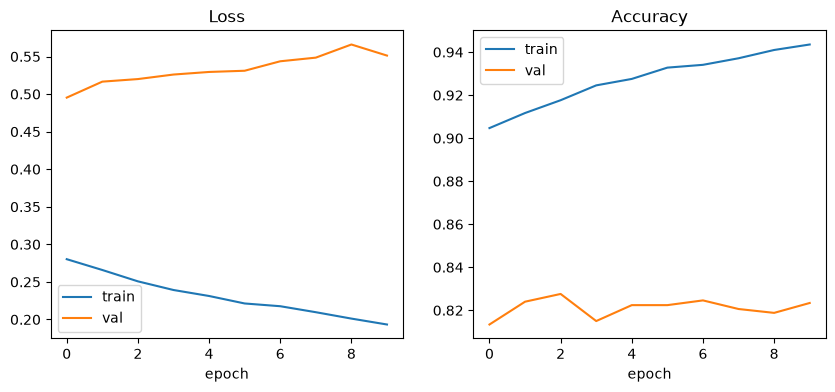

In [40]:
history_2 = fit(net_2, train_loader, val_loader, epochs=10, lr=1e-3, device=device)
plot_history(history_2)

## Results: LSTM (emb_dim=16, hidden_dim=32, max_len=200)

| Metric | Epoch 1 | Best | Epoch 10 |
|---|---|---|---|
| val acc | 0.813 | 0.828 (epoch 3) | 0.823 |
| train acc | 0.905 | | 0.944 |
| val loss | 0.495 | 0.495 (epoch 1) | 0.551 |

**Observation:** LSTM beats the Flatten network by ~10 points of validation accuracy (0.83 vs 0.73) with fewer parameters (166k vs 262k).
- Val accuracy plateaus at ~0.82 from epoch 2; val loss is lowest in epoch 1 and then slowly rises while train loss keeps falling, so there is mild overfitting (train-val gap ~12 points vs ~27 for Flatten).
- More epochs do not help; the best stopping point is around epoch 2-3.

**Why LSTM is better:** it reads words in order and shares weights across positions, so it can use context ("not good") and does not need a separate weight for every position like Flatten.

PIPLINE

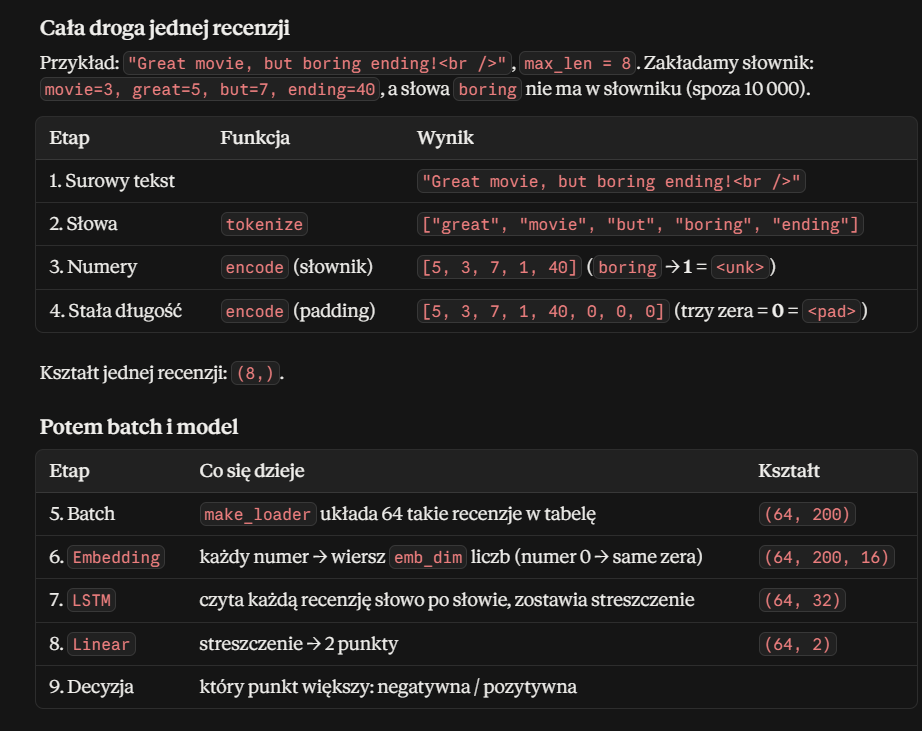

## Step 7. Experiments
- [ ] `run_experiment` + results table

| Experiment | What it tests |
|---|---|
| `nn.RNN` vs `nn.LSTM` | does LSTM handle long reviews better? |
| `max_len` 100 vs 400 | effect of sequence length |
| `hidden_dim` 32 vs 128 | model capacity |
| (optional) `bidirectional=True` | reading in both directions |
| (optional) pretrained GloVe in `Embedding` | transfer learning for words |